In [16]:
df_clean.to_csv(
    "../data/food_delivery_cleaned.csv",
    index=False
)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!


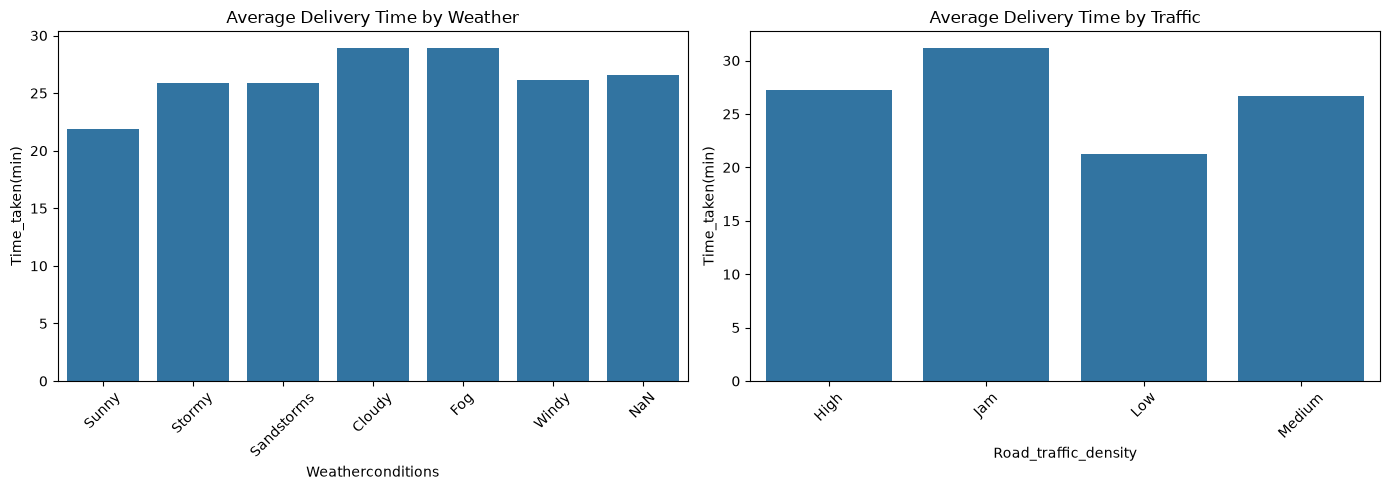

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=df_clean,
    x="Weatherconditions",
    y="Time_taken(min)",
    ax=axes[0],
    errorbar=None
)
axes[0].set_title("Average Delivery Time by Weather")
axes[0].tick_params(axis="x", rotation=45)

sns.barplot(
    data=df_clean,
    x="Road_traffic_density",
    y="Time_taken(min)",
    ax=axes[1],
    errorbar=None
)
axes[1].set_title("Average Delivery Time by Traffic")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [14]:
# Clean category names
df_clean["Weatherconditions"] = (
    df_clean["Weatherconditions"]
    .astype("string")
    .str.replace("conditions ", "", regex=False)
    .str.strip()
)

df_clean["Road_traffic_density"] = (
    df_clean["Road_traffic_density"]
    .astype("string")
    .str.replace("conditions ", "", regex=False)
    .str.strip()
)

# Business analysis
print("WEATHER ANALYSIS")
print(df_clean.groupby("Weatherconditions")["Time_taken(min)"].mean().round(2))

print("\nTRAFFIC ANALYSIS")
print(df_clean.groupby("Road_traffic_density")["Time_taken(min)"].mean().round(2))

print("\nCITY-WISE ORDERS")
print(df_clean["City"].value_counts())

WEATHER ANALYSIS
Weatherconditions
Cloudy        28.92
Fog           28.92
NaN           26.55
Sandstorms    25.88
Stormy        25.87
Sunny         21.86
Windy         26.12
Name: Time_taken(min), dtype: Float64

TRAFFIC ANALYSIS
Road_traffic_density
High      27.24
Jam       31.18
Low       21.27
Medium     26.7
Name: Time_taken(min), dtype: Float64

CITY-WISE ORDERS
City
Metropolitian     34093
Urban             10136
Semi-Urban          164
Name: count, dtype: int64


In [13]:
# Exploratory Data Analysis

print("FOOD DELIVERY ANALYSIS")
print("=" * 40)

# 1. Average Delivery Time
print("\nAverage Delivery Time:")
print(df_clean["Time_taken(min)"].mean())

# 2. Fastest and Slowest Delivery
print("\nMinimum Delivery Time:")
print(df_clean["Time_taken(min)"].min())

print("\nMaximum Delivery Time:")
print(df_clean["Time_taken(min)"].max())

# 3. Weather-wise Delivery Time
print("\nWeather-wise Average Delivery Time:")
print(df_clean.groupby("Weatherconditions")["Time_taken(min)"].mean().round(2))

# 4. Traffic-wise Delivery Time
print("\nTraffic-wise Average Delivery Time:")
print(df_clean.groupby("Road_traffic_density")["Time_taken(min)"].mean().round(2))

# 5. City-wise Orders
print("\nCity-wise Order Count:")
print(df_clean["City"].value_counts())

# 6. Delivery Partner Ratings
print("\nAverage Delivery Partner Rating:")
print(df_clean["Delivery_person_Ratings"].mean().round(2))

FOOD DELIVERY ANALYSIS

Average Delivery Time:
26.29460662821047

Minimum Delivery Time:
10

Maximum Delivery Time:
54

Weather-wise Average Delivery Time:
Weatherconditions
conditions Cloudy        28.92
conditions Fog           28.92
conditions NaN           26.55
conditions Sandstorms    25.88
conditions Stormy        25.87
conditions Sunny         21.86
conditions Windy         26.12
Name: Time_taken(min), dtype: Float64

Traffic-wise Average Delivery Time:
Road_traffic_density
High       27.24
Jam        31.18
Low        21.27
Medium      26.7
Name: Time_taken(min), dtype: Float64

City-wise Order Count:
City
Metropolitian     34093
Urban             10136
Semi-Urban          164
Name: count, dtype: int64

Average Delivery Partner Rating:
4.63


In [12]:
# Data Cleaning

df_clean = df.copy()

# Replace hidden missing values
df_clean = df_clean.replace(
    r'^\s*(NaN|nan|null|None)?\s*$',
    pd.NA,
    regex=True
)

# Convert numerical columns
numeric_cols = [
    "Delivery_person_Age",
    "Delivery_person_Ratings",
    "multiple_deliveries",
    "Time_taken(min)"
]

for col in numeric_cols:
    df_clean[col] = pd.to_numeric(
        df_clean[col].astype("string").str.replace(
            r'^\(min\)\s*', '', regex=True
        ),
        errors="coerce"
    )

# Convert date
df_clean["Order_Date"] = pd.to_datetime(
    df_clean["Order_Date"],
    errors="coerce",
    dayfirst=True
)

print("Data Cleaning Completed!")
print("Dataset Shape:", df_clean.shape)
print("Total Missing Values:", df_clean.isnull().sum().sum())
print("Duplicate Rows:", df_clean.duplicated().sum())

Data Cleaning Completed!
Dataset Shape: (45593, 20)
Total Missing Values: 8515
Duplicate Rows: 0


In [11]:
df[[
    "Delivery_person_Age",
    "Delivery_person_Ratings",
    "Vehicle_condition",
    "multiple_deliveries",
    "Time_taken(min)"
]].head(10)

,Delivery_person_Age,Delivery_person_Ratings,Vehicle_condition,multiple_deliveries,Time_taken(min)
0,37,4.9,2,0,(min) 24
1,34,4.5,2,1,(min) 33
2,23,4.4,0,1,(min) 26
3,38,4.7,0,1,(min) 21
4,32,4.6,1,1,(min) 30
5,22,4.8,0,1,(min) 26
6,33,4.7,1,1,(min) 40
7,35,4.6,2,1,(min) 32
8,22,4.8,0,1,(min) 34
9,36,4.2,2,3,(min) 46


In [10]:
df.dtypes

ID                                 str
Delivery_person_ID                 str
Delivery_person_Age                str
Delivery_person_Ratings            str
Restaurant_latitude            float64
Restaurant_longitude           float64
Delivery_location_latitude     float64
Delivery_location_longitude    float64
Order_Date                         str
Time_Orderd                        str
Time_Order_picked                  str
Weatherconditions                  str
Road_traffic_density               str
Vehicle_condition                int64
Type_of_order                      str
Type_of_vehicle                    str
multiple_deliveries                str
Festival                           str
City                               str
Time_taken(min)                    str
dtype: object

In [9]:
print("Total Duplicate Rows:", df.duplicated().sum())

Total Duplicate Rows: 0


In [8]:
for col in df.select_dtypes(include="object").columns:
    count = df[col].astype(str).str.strip().str.lower().isin(
        ["nan", "null", "none", ""]
    ).sum()

    if count > 0:
        print(col, ":", count)

C:\Users\atuls\AppData\Local\Temp\ipykernel_22160\2013402274.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


Delivery_person_Age : 1854
Delivery_person_Ratings : 1908
Time_Orderd : 1731
Road_traffic_density : 601
multiple_deliveries : 993
Festival : 228
City : 1200


In [7]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

Missing Values in Each Column:
ID                             0
Delivery_person_ID             0
Delivery_person_Age            0
Delivery_person_Ratings        0
Restaurant_latitude            0
Restaurant_longitude           0
Delivery_location_latitude     0
Delivery_location_longitude    0
Order_Date                     0
Time_Orderd                    0
Time_Order_picked              0
Weatherconditions              0
Road_traffic_density           0
Vehicle_condition              0
Type_of_order                  0
Type_of_vehicle                0
multiple_deliveries            0
Festival                       0
City                           0
Time_taken(min)                0
dtype: int64


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  str    
 1   Delivery_person_ID           45593 non-null  str    
 2   Delivery_person_Age          45593 non-null  str    
 3   Delivery_person_Ratings      45593 non-null  str    
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  str    
 9   Time_Orderd                  45593 non-null  str    
 10  Time_Order_picked            45593 non-null  str    
 11  Weatherconditions            45593 non-null  str    
 12  Road_traffic_density         45593 non-null  str    
 13  Vehicle_condition          

In [5]:
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

Total Rows: 45593
Total Columns: 20

Column Names:
['ID', 'Delivery_person_ID', 'Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 'Order_Date', 'Time_Orderd', 'Time_Order_picked', 'Weatherconditions', 'Road_traffic_density', 'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle', 'multiple_deliveries', 'Festival', 'City', 'Time_taken(min)']


In [4]:
df.head()

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:30:00,11:45:00,conditions Sunny,High,2,Snack,motorcycle,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:00,19:50:00,conditions Stormy,Jam,2,Snack,scooter,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,08:30:00,08:45:00,conditions Sandstorms,Low,0,Drinks,motorcycle,1,No,Urban,(min) 26
3,0x7a6a,COIMBRES13DEL02,38,4.7,11.003669,76.976494,11.053669,77.026494,05-04-2022,18:00:00,18:10:00,conditions Sunny,Medium,0,Buffet,motorcycle,1,No,Metropolitian,(min) 21
4,0x70a2,CHENRES12DEL01,32,4.6,12.972793,80.249982,13.012793,80.289982,26-03-2022,13:30:00,13:45:00,conditions Cloudy,High,1,Snack,scooter,1,No,Metropolitian,(min) 30


In [2]:
df = pd.read_csv("../data/food_delivery_train.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Food Delivery Analytics Project Started!")

Food Delivery Analytics Project Started!
